In [1]:
import os
from pyspark.sql import SparkSession

# MinIO commun de l'equipe : un seul bucket, prefixes bronze/ silver/ gold/ (valeurs dans .env)
MINIO_ENDPOINT = os.getenv("MINIO_ENDPOINT", "http://minio:9000")
MINIO_ACCESS_KEY = os.getenv("MINIO_ACCESS_KEY", "urbanhub")
MINIO_SECRET_KEY = os.getenv("MINIO_SECRET_KEY", "urbanhub123")
BUCKET = os.getenv("MINIO_BUCKET", "urbanhub")
LAKE = f"s3a://{BUCKET}"

spark = SparkSession.builder \
    .appName("UrbanHub - Meteo") \
    .config("spark.driver.memory", "4g") \
    .config("spark.jars.packages", "org.apache.hadoop:hadoop-aws:3.3.4,com.amazonaws:aws-java-sdk-bundle:1.12.262") \
    .config("spark.hadoop.fs.s3a.endpoint", MINIO_ENDPOINT) \
    .config("spark.hadoop.fs.s3a.access.key", MINIO_ACCESS_KEY) \
    .config("spark.hadoop.fs.s3a.secret.key", MINIO_SECRET_KEY) \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled", "false") \
    .config("spark.sql.session.timeZone", "UTC") \
    .getOrCreate()

print("Spark pret :", spark.version, "| data lake :", LAKE)

Spark pret : 3.5.1 | data lake : s3a://urbanhub


In [2]:
import pyarrow as pa
import pyarrow.parquet as pq
from pyarrow import fs

s3 = fs.S3FileSystem(endpoint_override=MINIO_ENDPOINT.split("://")[1], scheme=MINIO_ENDPOINT.split("://")[0],
                     access_key=MINIO_ACCESS_KEY, secret_key=MINIO_SECRET_KEY,
                     region="us-east-1")

COLONNES = ["STATION", "DATE", "LATITUDE", "LONGITUDE", "NAME",
            "WND", "VIS", "TMP", "SLP", "AA1"]
schema_texte = pa.schema([(c, pa.string()) for c in COLONNES])

fichiers = [f.path for f in s3.get_file_info(fs.FileSelector(f"{BUCKET}/bronze/meteo", recursive=True))
            if f.path.endswith(".parquet")]

corriges = 0
for chemin in fichiers:
    table = pq.read_table(chemin, filesystem=s3)
    if table.schema != schema_texte:
        pq.write_table(table.cast(schema_texte), chemin, filesystem=s3)
        corriges += 1

print(f"{len(fichiers)} fichiers verifies, {corriges} corriges")

1027 fichiers verifies, 0 corriges


In [3]:
from pyspark.sql import functions as F

bronze = spark.read \
    .option("basePath", f"{LAKE}/bronze/meteo/") \
    .parquet(f"{LAKE}/bronze/meteo/annee=*")

print("Lignes en Bronze :", bronze.count())
bronze.show(5, truncate=False)

Lignes en Bronze : 14028602
+-----------+-------------------+---------+---------+-------------------+--------------+------------+-------+-------+-----------+-----+
|STATION    |DATE               |LATITUDE |LONGITUDE|NAME               |WND           |VIS         |TMP    |SLP    |AA1        |annee|
+-----------+-------------------+---------+---------+-------------------+--------------+------------+-------+-------+-----------+-----+
|07038034061|2022-01-01T00:00:00|49.028669|1.219864 |EVREUX FAUVILLE, FR|210,1,N,0057,1|006000,1,9,9|+0119,1|10257,1|03,0000,9,1|2022 |
|07038034061|2022-01-01T00:00:00|49.028669|1.219864 |EVREUX FAUVILLE, FR|210,1,N,0057,1|007000,1,9,9|+0120,1|99999,9|NULL       |2022 |
|07038034061|2022-01-01T00:30:00|49.028669|1.219864 |EVREUX FAUVILLE, FR|200,1,N,0031,1|006000,1,9,9|+0120,1|99999,9|NULL       |2022 |
|07038034061|2022-01-01T01:00:00|49.028669|1.219864 |EVREUX FAUVILLE, FR|200,1,N,0036,1|005000,1,9,9|+0117,1|10251,1|01,0000,9,1|2022 |
|07038034061|2022-01

In [4]:
def decoder(colonne, position, manquant, diviseur=1.0, position_qualite=None):
    """Extrait une valeur d'une colonne NOAA codee (ex : TMP '+0119,1').
    - manquant : code NOAA de valeur manquante (9999, 99999...) -> vide
    - position_qualite : codes qualite 2,3,6,7 = mesure douteuse -> vide"""
    morceaux = F.split(F.col(colonne), ",")
    valeur = F.regexp_replace(morceaux.getItem(position), "\\+", "").cast("double")
    invalide = valeur.isNull() | (F.abs(valeur) == manquant)
    if position_qualite is not None:
        invalide = invalide | morceaux.getItem(position_qualite).isin("2", "3", "6", "7")
    return F.when(invalide, None).otherwise(valeur / diviseur)


# 1) Decodage des colonnes et conversion des unites
decode = bronze.select(
    F.col("STATION").alias("station_id"),
    F.col("NAME").alias("station_name"),
    F.col("LATITUDE").cast("double").alias("latitude"),
    F.col("LONGITUDE").cast("double").alias("longitude"),
    F.to_timestamp("DATE", "yyyy-MM-dd'T'HH:mm:ss").alias("timestamp"),
    decoder("TMP", 0, 9999, 10, 1).alias("temperature"),           # degres C
    decoder("WND", 3, 9999, 10, 4).alias("wind_speed"),            # m/s
    decoder("WND", 0, 999, 1, 1).alias("wind_direction"),          # degres
    decoder("SLP", 0, 99999, 10, 1).alias("pressure"),             # hPa
    decoder("VIS", 0, 999999, 1, 1).alias("visibility"),           # metres
    decoder("AA1", 1, 9999, 10, 3).alias("precipitation"),         # mm
    decoder("AA1", 0, 99).alias("precipitation_period_h"),         # heures
    F.col("annee"),
)

# 2) Valeurs physiquement impossibles -> vide
limites = {"temperature": (-50, 50), "wind_speed": (0, 75),
           "pressure": (870, 1090), "visibility": (0, 160000),
           "precipitation": (0, 300)}
for colonne, (mini, maxi) in limites.items():
    decode = decode.withColumn(colonne,
        F.when(F.col(colonne).between(mini, maxi), F.col(colonne)))

# 3) Doublons : une seule ligne par station et par heure de mesure
mesures = ["temperature", "wind_speed", "wind_direction", "pressure",
           "visibility", "precipitation", "precipitation_period_h"]
silver = decode.filter(F.col("timestamp").isNotNull()) \
    .groupBy("station_id", "timestamp", "annee") \
    .agg(F.first("station_name", True).alias("station_name"),
         F.first("latitude", True).alias("latitude"),
         F.first("longitude", True).alias("longitude"),
         *[F.first(c, True).alias(c) for c in mesures])

silver.show(5, truncate=False)

+-----------+-------------------+-----+------------+----------+---------+-----------+----------+--------------+--------+----------+-------------+----------------------+
|station_id |timestamp          |annee|station_name|latitude  |longitude|temperature|wind_speed|wind_direction|pressure|visibility|precipitation|precipitation_period_h|
+-----------+-------------------+-----+------------+----------+---------+-----------+----------+--------------+--------+----------+-------------+----------------------+
|07002099999|2021-01-01 22:00:00|2021 |BOULOGNE, FR|50.7333333|1.6      |3.2        |1.0       |190.0         |1013.6  |NULL      |0.0          |1.0                   |
|07002099999|2021-01-02 01:00:00|2021 |BOULOGNE, FR|50.7333333|1.6      |2.8        |2.1       |130.0         |1013.8  |NULL      |0.0          |1.0                   |
|07002099999|2021-01-02 02:00:00|2021 |BOULOGNE, FR|50.7333333|1.6      |3.2        |1.5       |130.0         |1014.0  |NULL      |0.0          |1.0       

In [5]:
# 1) Centres des 5 villes choisies par l'equipe
villes = spark.createDataFrame([
    ("Paris", 48.857, 2.352), ("Lyon", 45.764, 4.836),
    ("Marseille", 43.297, 5.370), ("Toulouse", 43.605, 1.444),
    ("Bordeaux", 44.838, -0.579),
], ["city", "city_lat", "city_lon"])

# 2) Distance (km) de chaque station au centre de chaque ville (formule de Haversine)
stations = silver.select("station_id", "latitude", "longitude").dropDuplicates(["station_id"])
dlat = F.radians(F.col("city_lat") - F.col("latitude"))
dlon = F.radians(F.col("city_lon") - F.col("longitude"))
a = F.sin(dlat / 2) ** 2 + F.cos(F.radians("latitude")) * F.cos(F.radians("city_lat")) * F.sin(dlon / 2) ** 2
distance_km = 2 * 6371 * F.asin(F.sqrt(a))

stations_villes = stations.crossJoin(villes) \
    .withColumn("distance_km", distance_km) \
    .filter(F.col("distance_km") <= 30) \
    .select("station_id", "city", F.round("distance_km", 1).alias("distance_km"))

# 3) Ajout de la colonne "city" (vide pour les stations hors des 5 villes)
silver_final = silver.join(stations_villes.select("station_id", "city"), "station_id", "left")

# 4) Convention equipe : timestamp en UTC + date / heure de Paris pour les jointures
paris = F.from_utc_timestamp("timestamp", "Europe/Paris")
silver_final = silver_final.withColumn("date_local", F.to_date(paris)) \
                           .withColumn("hour_local", F.hour(paris))

# 5) Ecriture dans la couche Silver, partitionnee par annee
silver_final.write.mode("overwrite").partitionBy("annee").parquet(f"{LAKE}/silver/meteo/")
print("Couche Silver ecrite dans", LAKE + "/silver/meteo/")

# 6) Verification
verif = spark.read.parquet(f"{LAKE}/silver/meteo/")
print("Lignes en Silver :", verif.count())
stations_villes.orderBy("city", "distance_km").show(30, truncate=False)

Couche Silver ecrite dans s3a://urbanhub/silver/meteo/
Lignes en Silver : 11076139
+-----------+---------+-----------+
|station_id |city     |distance_km|
+-----------+---------+-----------+
|07510099999|Bordeaux |10.8       |
|07480099999|Lyon     |9.3        |
|07481099999|Lyon     |20.2       |
|07650099999|Marseille|19.9       |
|07656099999|Marseille|21.4       |
|07653099999|Marseille|26.2       |
|07156099999|Paris    |4.7        |
|07154099999|Paris    |12.6       |
|07150099999|Paris    |14.1       |
|07147099999|Paris    |14.3       |
|07149099999|Paris    |14.7       |
|07146099999|Paris    |21.5       |
|07157099999|Paris    |22.6       |
|07145099999|Paris    |27.7       |
|07630099999|Toulouse |7.0        |
|07631099999|Toulouse |9.0        |
|07629399999|Toulouse |22.7       |
|07628099999|Toulouse |23.3       |
+-----------+---------+-----------+



In [6]:
silver = spark.read.parquet(f"{LAKE}/silver/meteo/")
s = silver.withColumn("date", F.to_date("timestamp"))

def pluie_sur(heures):
    """Somme des pluies mesurees sur une periode donnee (1h, 3h, 6h...)."""
    return F.sum(F.when(F.col("precipitation_period_h") == heures, F.col("precipitation")))

journalier = s.groupBy("station_id", "city", "date").agg(
    F.first("station_name", True).alias("station_name"),
    F.first("latitude", True).alias("latitude"),
    F.first("longitude", True).alias("longitude"),
    F.round(F.avg("temperature"), 1).alias("temp_moy"),
    F.min("temperature").alias("temp_min"),
    F.max("temperature").alias("temp_max"),
    F.round(F.avg("wind_speed"), 1).alias("vent_moy"),
    F.max("wind_speed").alias("vent_max"),
    F.round(F.avg("pressure"), 1).alias("pression_moy"),
    F.round(F.avg("visibility"), 0).alias("visibilite_moy"),
    F.count("temperature").alias("nb_mesures"),
    F.round(F.coalesce(pluie_sur(1), pluie_sur(3), pluie_sur(6), pluie_sur(12),
                       F.max(F.when(F.col("precipitation_period_h") == 24,
                                    F.col("precipitation")))), 1).alias("pluie_mm"),
).withColumn("annee", F.year("date")).withColumn("mois", F.month("date"))

journalier.write.mode("overwrite").partitionBy("annee") \
    .parquet(f"{LAKE}/gold/meteo/journalier/")

journalier = spark.read.parquet(f"{LAKE}/gold/meteo/journalier/")
print("Jours x stations :", journalier.count())
journalier.filter(F.col("city") == "Paris").orderBy("date").show(5)

Jours x stations : 304269
+-----------+-----+----------+--------------------+----------+---------+--------+--------+--------+--------+--------+------------+--------------+----------+--------+----+-----+
| station_id| city|      date|        station_name|  latitude|longitude|temp_moy|temp_min|temp_max|vent_moy|vent_max|pression_moy|visibilite_moy|nb_mesures|pluie_mm|mois|annee|
+-----------+-----+----------+--------------------+----------+---------+--------+--------+--------+--------+--------+------------+--------------+----------+--------+----+-----+
|07157099999|Paris|2021-01-01|CHARLES DE GAULLE...| 49.012779|     2.55|     0.8|    -1.0|     3.0|     2.0|     2.6|      1011.2|        9885.0|        48|     0.0|   1| 2021|
|07149099999|Paris|2021-01-01|            ORLY, FR| 48.725278| 2.359444|     0.6|    -2.2|     4.0|     1.6|     3.1|      1011.2|       10062.0|        48|     0.2|   1| 2021|
|07156099999|Paris|2021-01-01|PARIS MONTSOURIS, FR|48.8166666|2.3333333|     2.2|     0.6

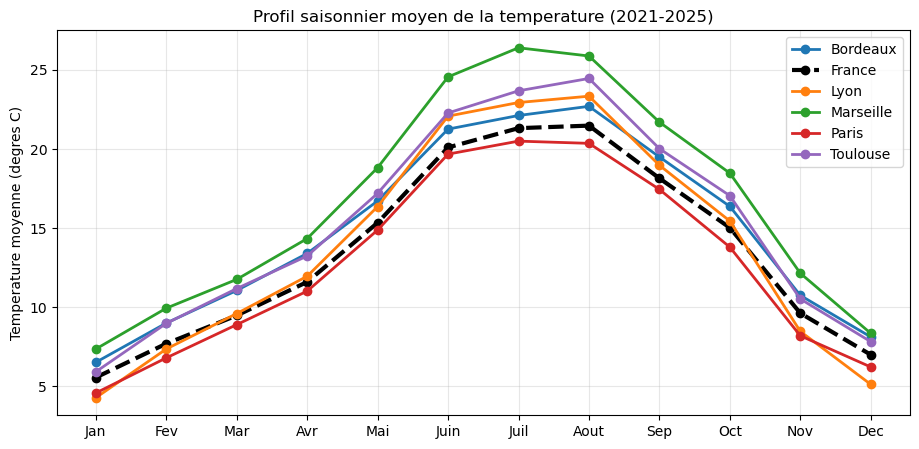

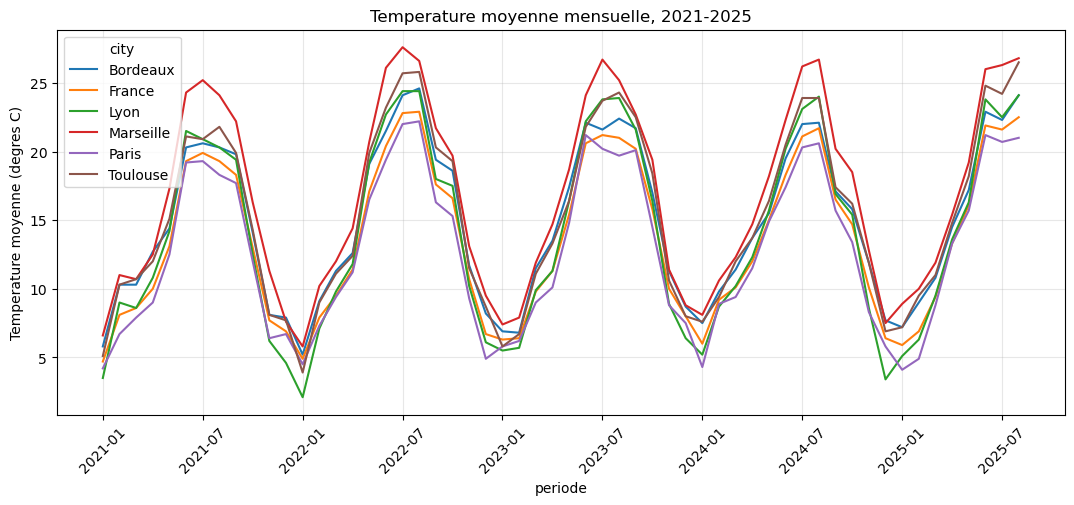

city  Bordeaux  France  Lyon  Marseille  Paris  Toulouse
mois                                                    
1          6.5     5.6   4.3        7.4    4.6       5.9
2          9.0     7.7   7.4        9.9    6.8       9.0
3         11.1     9.5   9.6       11.8    8.9      11.2
4         13.4    11.6  12.0       14.3   11.0      13.2
5         16.7    15.3  16.4       18.8   14.9      17.2
6         21.3    20.1  22.1       24.6   19.7      22.3
7         22.1    21.3  22.9       26.4   20.5      23.7
8         22.7    21.5  23.3       25.9   20.4      24.5
9         19.5    18.2  19.0       21.7   17.4      20.0
10        16.4    15.0  15.4       18.5   13.8      17.0
11        10.8     9.6   8.5       12.2    8.2      10.5
12         8.1     7.0   5.1        8.4    6.2       7.8


In [7]:
import matplotlib.pyplot as plt

# Jours fiables : au moins 12 mesures dans la journee
fiables = journalier.filter(F.col("nb_mesures") >= 12)

# Temperature moyenne par mois : 5 villes + France entiere
villes_mois = fiables.filter(F.col("city").isNotNull()) \
    .groupBy("city", "annee", "mois") \
    .agg(F.round(F.avg("temp_moy"), 1).alias("temp_moy"))
france_mois = fiables.groupBy("annee", "mois") \
    .agg(F.round(F.avg("temp_moy"), 1).alias("temp_moy")) \
    .withColumn("city", F.lit("France"))
mensuel = villes_mois.unionByName(france_mois)
mensuel.write.mode("overwrite").parquet(f"{LAKE}/gold/meteo/temperature_mensuelle/")

pdf = mensuel.toPandas()

# Graphique 1 : profil saisonnier moyen (moyenne des 5 annees, mois par mois)
saison = pdf.groupby(["mois", "city"])["temp_moy"].mean().unstack("city")
fig, ax = plt.subplots(figsize=(11, 5))
for ville in saison.columns:
    style = {"color": "black", "linewidth": 3, "linestyle": "--"} if ville == "France" else {"linewidth": 2}
    ax.plot(saison.index, saison[ville], marker="o", label=ville, **style)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Fev", "Mar", "Avr", "Mai", "Juin",
                    "Juil", "Aout", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Temperature moyenne (degres C)")
ax.set_title("Profil saisonnier moyen de la temperature (2021-2025)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# Graphique 2 : evolution mois par mois sur les 5 ans
pdf["periode"] = pdf["annee"].astype(str) + "-" + pdf["mois"].astype(str).str.zfill(2)
evolution = pdf.pivot_table(index="periode", columns="city", values="temp_moy").sort_index()
fig, ax = plt.subplots(figsize=(13, 5))
evolution.plot(ax=ax, linewidth=1.5)
ax.set_xticks(range(0, len(evolution), 6))
ax.set_xticklabels(evolution.index[::6], rotation=45)
ax.set_ylabel("Temperature moyenne (degres C)")
ax.set_title("Temperature moyenne mensuelle, 2021-2025")
ax.grid(alpha=0.3)
plt.show()

print(saison.round(1))

+------------+------------+
|premier_jour|dernier_jour|
+------------+------------+
|  2021-01-01|  2025-08-24|
+------------+------------+



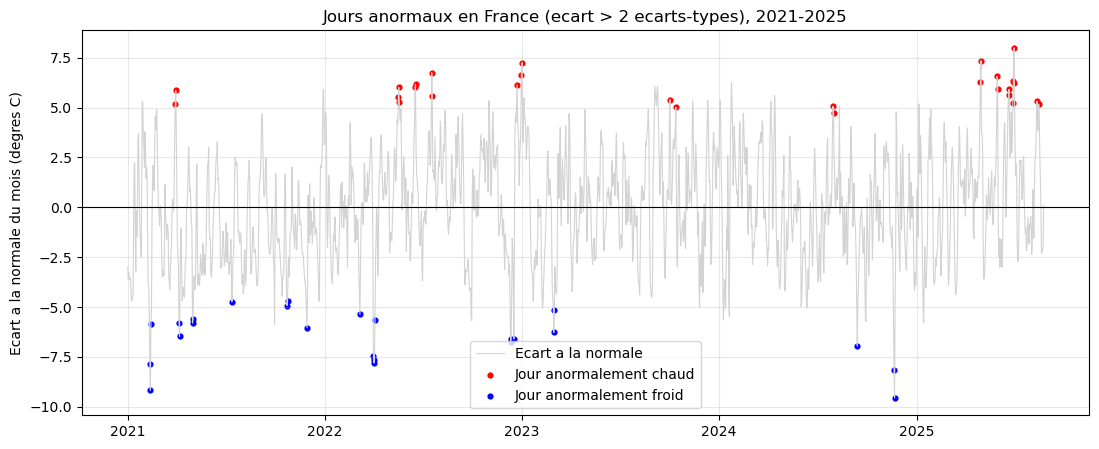

Jours anormalement chauds : 28, froids : 24
    type      debut        fin  nb_jours  ecart_max
0  froid 2021-02-11 2021-02-13         3        9.2
1  froid 2022-04-01 2022-04-04         4        7.8
2  chaud 2022-05-17 2022-05-19         3        6.0
3  chaud 2025-06-28 2025-07-01         4        8.0


In [8]:
import numpy as np
import pandas as pd

# Verification : periode couverte par les donnees
journalier.agg(F.min("date").alias("premier_jour"),
               F.max("date").alias("dernier_jour")).show()

# 1) Temperature moyenne de la France, jour par jour
fj = fiables.groupBy("date").agg(F.avg("temp_moy").alias("temp")) \
    .toPandas().sort_values("date").reset_index(drop=True)
fj["date"] = pd.to_datetime(fj["date"])
fj["mois"] = fj["date"].dt.month

# 2) Normale de chaque mois (moyenne et ecart-type sur les 5 ans)
normale = fj.groupby("mois")["temp"].agg(normale="mean", ecart_type="std")
fj = fj.join(normale, on="mois")
fj["ecart"] = fj["temp"] - fj["normale"]
fj["z"] = fj["ecart"] / fj["ecart_type"]
fj["anomalie"] = np.select([fj["z"] >= 2, fj["z"] <= -2], ["chaud", "froid"], "normal")

# 3) Periodes anormales : au moins 3 jours anormaux consecutifs du meme type
fj["groupe"] = (fj["anomalie"] != fj["anomalie"].shift()).cumsum()
periodes = fj[fj["anomalie"] != "normal"].groupby("groupe").agg(
    type=("anomalie", "first"), debut=("date", "min"), fin=("date", "max"),
    nb_jours=("date", "count"), ecart_max=("ecart", lambda s: round(s.abs().max(), 1)))
periodes = periodes[periodes["nb_jours"] >= 3].sort_values("debut").reset_index(drop=True)

# 4) Sauvegarde dans Gold
spark.createDataFrame(fj[["date", "temp", "normale", "ecart", "z", "anomalie"]]) \
    .write.mode("overwrite").parquet(f"{LAKE}/gold/meteo/anomalies_france/")

# 5) Graphique
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(fj["date"], fj["ecart"], color="lightgray", linewidth=0.8, label="Ecart a la normale")
chaud, froid = fj[fj["anomalie"] == "chaud"], fj[fj["anomalie"] == "froid"]
ax.scatter(chaud["date"], chaud["ecart"], color="red", s=12, label="Jour anormalement chaud")
ax.scatter(froid["date"], froid["ecart"], color="blue", s=12, label="Jour anormalement froid")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Ecart a la normale du mois (degres C)")
ax.set_title("Jours anormaux en France (ecart > 2 ecarts-types), 2021-2025")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print(f"Jours anormalement chauds : {len(chaud)}, froids : {len(froid)}")
print(periodes.to_string())

Nombre de jours extremes par ville (2021 - aout 2025) :
           forte_chaleur  grand_froid  vent_violent  fortes_pluies
city                                                              
Bordeaux              49            3             1              1
Lyon                  52           18             3              6
Marseille             55            0            74              0
Paris                 15           12             2              2
Toulouse              72           10             4              0


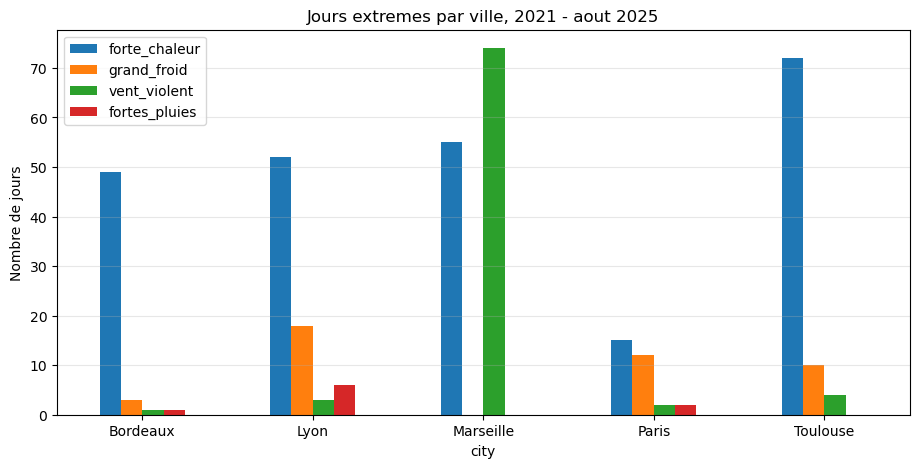


=== Jours les plus chauds ===
+----------+-----------------------+--------+--------+
|date      |station_name           |city    |temp_max|
+----------+-----------------------+--------+--------+
|2023-08-23|SALVAZA, FR            |NULL    |43.0    |
|2022-06-18|ANGLET, FR             |NULL    |43.0    |
|2022-07-18|BISCAROSSE PARENTIS, FR|NULL    |43.0    |
|2023-08-23|BLAGNAC, FR            |Toulouse|42.3    |
|2023-08-24|MONTAUBAN, FR          |NULL    |42.2    |
+----------+-----------------------+--------+--------+
only showing top 5 rows


=== Jours les plus froids ===
+----------+-----------------+----+--------+
|date      |station_name     |city|temp_min|
+----------+-----------------+----+--------+
|2022-12-17|MIRECOURT, FR    |NULL|-16.0   |
|2021-02-14|BALE MULHOUSE, FR|NULL|-16.0   |
|2021-02-14|SAINT SAUVEUR, FR|NULL|-13.0   |
|2022-12-17|OCHEY, FR        |NULL|-13.0   |
|2022-12-16|MIRECOURT, FR    |NULL|-13.0   |
+----------+-----------------+----+--------+
only showing 

In [9]:
# 1) Une ligne par ville et par jour : la valeur la plus extreme de ses stations
vj = fiables.filter(F.col("city").isNotNull()) \
    .groupBy("city", "date", "annee").agg(
        F.max("temp_max").alias("temp_max"),
        F.min("temp_min").alias("temp_min"),
        F.max("vent_max").alias("vent_max"),
        F.max("pluie_mm").alias("pluie_mm")) \
    .withColumn("forte_chaleur", (F.col("temp_max") >= 35).cast("int")) \
    .withColumn("grand_froid", (F.col("temp_min") <= -5).cast("int")) \
    .withColumn("vent_violent", (F.col("vent_max") >= 17).cast("int")) \
    .withColumn("fortes_pluies", (F.col("pluie_mm") >= 40).cast("int"))

types = ["forte_chaleur", "grand_froid", "vent_violent", "fortes_pluies"]
extremes = vj.filter(sum(F.coalesce(F.col(t), F.lit(0)) for t in types) > 0)
extremes.write.mode("overwrite").parquet(f"{LAKE}/gold/meteo/jours_extremes_villes/")

# 2) Nombre de jours extremes par ville
compte = vj.groupBy("city").agg(*[F.sum(t).alias(t) for t in types]) \
    .orderBy("city").toPandas().set_index("city")
print("Nombre de jours extremes par ville (2021 - aout 2025) :")
print(compte)

compte.plot(kind="bar", figsize=(11, 5), rot=0)
plt.ylabel("Nombre de jours")
plt.title("Jours extremes par ville, 2021 - aout 2025")
plt.grid(axis="y", alpha=0.3)
plt.show()

# 3) Records en France (toutes stations)
records = [("Jours les plus chauds", "temp_max", False),
           ("Jours les plus froids", "temp_min", True),
           ("Vent le plus fort", "vent_max", False),
           ("Plus fortes pluies", "pluie_mm", False)]
for titre, col, croissant in records:
    print(f"\n=== {titre} ===")
    ordre = F.col(col).asc() if croissant else F.col(col).desc()
    fiables.filter(F.col(col).isNotNull()).orderBy(ordre) \
        .select("date", "station_name", "city", col).show(5, truncate=False)

               correlation avec la visibilite
temperature                             0.129
wind_speed                              0.028
pressure                               -0.091
precipitation                          -0.112


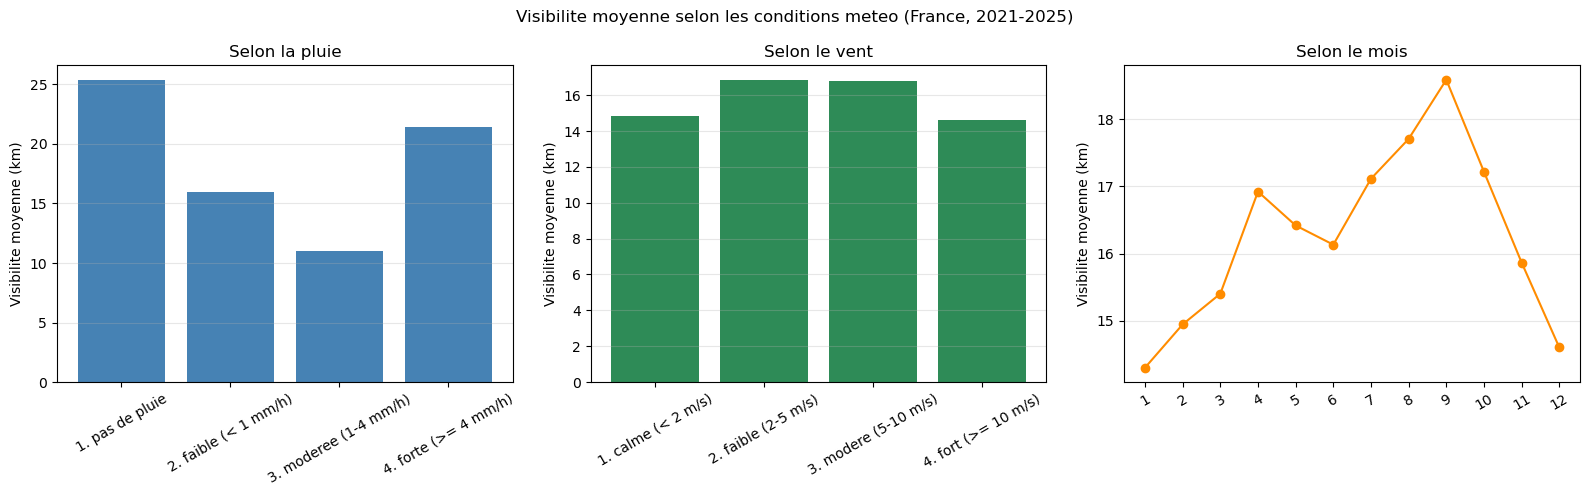

                  classe  visibilite_km
0        1. pas de pluie      25.337838
1   2. faible (< 1 mm/h)      15.953241
2  3. moderee (1-4 mm/h)      11.024476
3   4. forte (>= 4 mm/h)      21.387471 

                 classe  visibilite_km
0    1. calme (< 2 m/s)      14.818016
1   2. faible (2-5 m/s)      16.822805
2  3. modere (5-10 m/s)      16.774117
3   4. fort (>= 10 m/s)      14.638304 

    mois  visibilite_km
0      1      14.302264
1      2      14.946279
2      3      15.402457
3      4      16.920770
4      5      16.417110
5      6      16.131537
6      7      17.111863
7      8      17.704334
8      9      18.584384
9     10      17.216117
10    11      15.865491
11    12      14.603350


In [10]:
silver = spark.read.parquet(f"{LAKE}/silver/meteo/")
vis = silver.filter(F.col("visibility").isNotNull())

# 1) Correlations (sur les mesures horaires)
variables = ["temperature", "wind_speed", "pressure", "precipitation"]
corr = vis.select(*[F.round(F.corr("visibility", v), 3).alias(v) for v in variables]).toPandas().T
corr.columns = ["correlation avec la visibilite"]
print(corr)

# 2) Visibilite moyenne par classe de pluie (mesures sur 1 heure)
pluie = vis.filter(F.col("precipitation_period_h") == 1).withColumn("classe",
    F.when(F.col("precipitation") == 0, "1. pas de pluie")
     .when(F.col("precipitation") < 1, "2. faible (< 1 mm/h)")
     .when(F.col("precipitation") < 4, "3. moderee (1-4 mm/h)")
     .otherwise("4. forte (>= 4 mm/h)")) \
    .groupBy("classe").agg((F.avg("visibility") / 1000).alias("visibilite_km")) \
    .orderBy("classe").toPandas()

# 3) Visibilite moyenne par classe de vent
vent = vis.filter(F.col("wind_speed").isNotNull()).withColumn("classe",
    F.when(F.col("wind_speed") < 2, "1. calme (< 2 m/s)")
     .when(F.col("wind_speed") < 5, "2. faible (2-5 m/s)")
     .when(F.col("wind_speed") < 10, "3. modere (5-10 m/s)")
     .otherwise("4. fort (>= 10 m/s)")) \
    .groupBy("classe").agg((F.avg("visibility") / 1000).alias("visibilite_km")) \
    .orderBy("classe").toPandas()

# 4) Visibilite moyenne par mois
mois = vis.withColumn("mois", F.month("timestamp")).groupBy("mois") \
    .agg((F.avg("visibility") / 1000).alias("visibilite_km")).orderBy("mois").toPandas()

# 5) Graphiques
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].bar(pluie["classe"], pluie["visibilite_km"], color="steelblue")
axes[0].set_title("Selon la pluie")
axes[1].bar(vent["classe"], vent["visibilite_km"], color="seagreen")
axes[1].set_title("Selon le vent")
axes[2].plot(mois["mois"], mois["visibilite_km"], marker="o", color="darkorange")
axes[2].set_xticks(range(1, 13))
axes[2].set_title("Selon le mois")
for ax in axes:
    ax.set_ylabel("Visibilite moyenne (km)")
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Visibilite moyenne selon les conditions meteo (France, 2021-2025)")
plt.tight_layout()
plt.show()

print(pluie, "\n")
print(vent, "\n")
print(mois)